In [1]:
#comparision of the tested models before choosing the main model#

In [2]:
# Libraries
import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D
from sklearn.preprocessing import StandardScaler
import os
#os.chdir('..')
get_ipython().run_line_magic('matplotlib', 'inline')
import json
import glob

In [3]:
data = pd.read_csv("data/data_selected_new_existing.csv")
print(data.columns)
# categorical_vars = [
#     'country',
#        'country_name', 'ECD', 'residence',
#        'HH_head_sex', 'internet_use', 'health_insurance', 'child_sex',
#        'stunted', 'wasted', 'overwt', 'underwt', 'child_age',
#        'birth_order', 'baby_postnatal_check',
#        'birth_wt', 'drug_intestinal_parasite', 'diarrhea',
#        'cough', 'EaChDisease', 'current_age', 'education_level', 'fathers_edu',
#        'marital_status', 'number_ANC', 'working_status', 'wealth_Index',
#        'distance_to_facility', 'No_HH_Member', 'media_exposure'
# ]

# for col in categorical_vars:
#     if col in data.columns:
#         data[col] = data[col].astype("category")

Index(['ECD', 'child_sex', 'child_age', 'birth_order',
       'preceding_birth_interval', 'baby_postnatal_check', 'birth_wt',
       'supplemented_VitA', 'drug_intestinal_parasite', 'EaChDisease', 'cough',
       'diarrhea', 'stunted', 'underwt', 'wasted', 'overwt', 'current_age',
       'education_level', 'fathers_edu', 'marital_status', 'number_ANC',
       'working_status', 'wealth_Index', 'No_HH_Member', 'health_insurance',
       'distance_to_facility', 'water_source', 'sanitation_facility',
       'HH_head_sex', 'media_exposure', 'internet_use',
       'frequency_internet_use', 'residence'],
      dtype='str')


In [4]:
#summary of the data
# data= data.drop('v005', axis=1)
# data= data.drop('caseid', axis=1)
# data= data.drop('country_name', axis=1)
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 7411 entries, 0 to 7410
Data columns (total 33 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   ECD                       7411 non-null   int64
 1   child_sex                 7411 non-null   str  
 2   child_age                 7411 non-null   str  
 3   birth_order               7411 non-null   str  
 4   preceding_birth_interval  7393 non-null   str  
 5   baby_postnatal_check      1865 non-null   str  
 6   birth_wt                  2388 non-null   str  
 7   supplemented_VitA         4617 non-null   str  
 8   drug_intestinal_parasite  4617 non-null   str  
 9   EaChDisease               7411 non-null   str  
 10  cough                     7411 non-null   str  
 11  diarrhea                  7411 non-null   str  
 12  stunted                   2674 non-null   str  
 13  underwt                   2693 non-null   str  
 14  wasted                    2639 non-null   str  
 15

In [5]:
#see the missing values
data.isnull().sum()

ECD                            0
child_sex                      0
child_age                      0
birth_order                    0
preceding_birth_interval      18
baby_postnatal_check        5546
birth_wt                    5023
supplemented_VitA           2794
drug_intestinal_parasite    2794
EaChDisease                    0
cough                          0
diarrhea                       0
stunted                     4737
underwt                     4718
wasted                      4772
overwt                      4772
current_age                    0
education_level                0
fathers_edu                  804
marital_status                 0
number_ANC                  5546
working_status                 0
wealth_Index                   0
No_HH_Member                   0
health_insurance            4617
distance_to_facility           0
water_source                2135
sanitation_facility            0
HH_head_sex                    0
media_exposure                 0
internet_u

<Axes: >

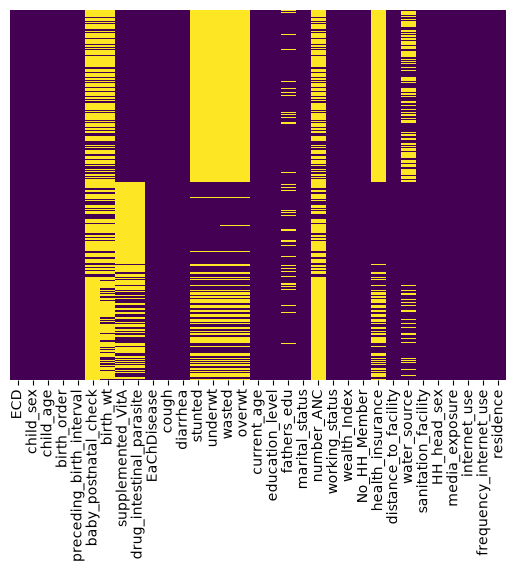

In [6]:
#see the heatmap of missing values
sns.heatmap(data.isnull(),yticklabels=False,cbar=False,cmap='viridis')

<Axes: xlabel='ECD', ylabel='count'>

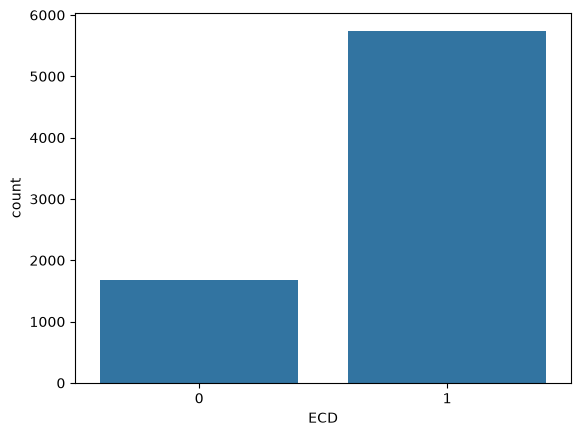

In [7]:
# see the nature of outcome variable's class imbalance
sns.countplot(x='ECD', data=data) #The imbalance is fair in our case

In [8]:
#dropping a variable with missing >=40%#
data= data.drop('birth_wt', axis=1)
data= data.drop('baby_postnatal_check', axis=1)
data= data.drop('stunted', axis=1)
data= data.drop('wasted', axis=1)
data= data.drop('underwt', axis=1)
data= data.drop('overwt', axis=1)
data= data.drop('number_ANC', axis=1)
data= data.drop('fathers_edu', axis=1)
data= data.drop('health_insurance', axis=1)
data= data.drop('frequency_internet_use', axis=1)
#Extra variables with missing values
data= data.drop('water_source', axis=1)
data= data.drop('drug_intestinal_parasite', axis=1)
data= data.drop('supplemented_VitA', axis=1)

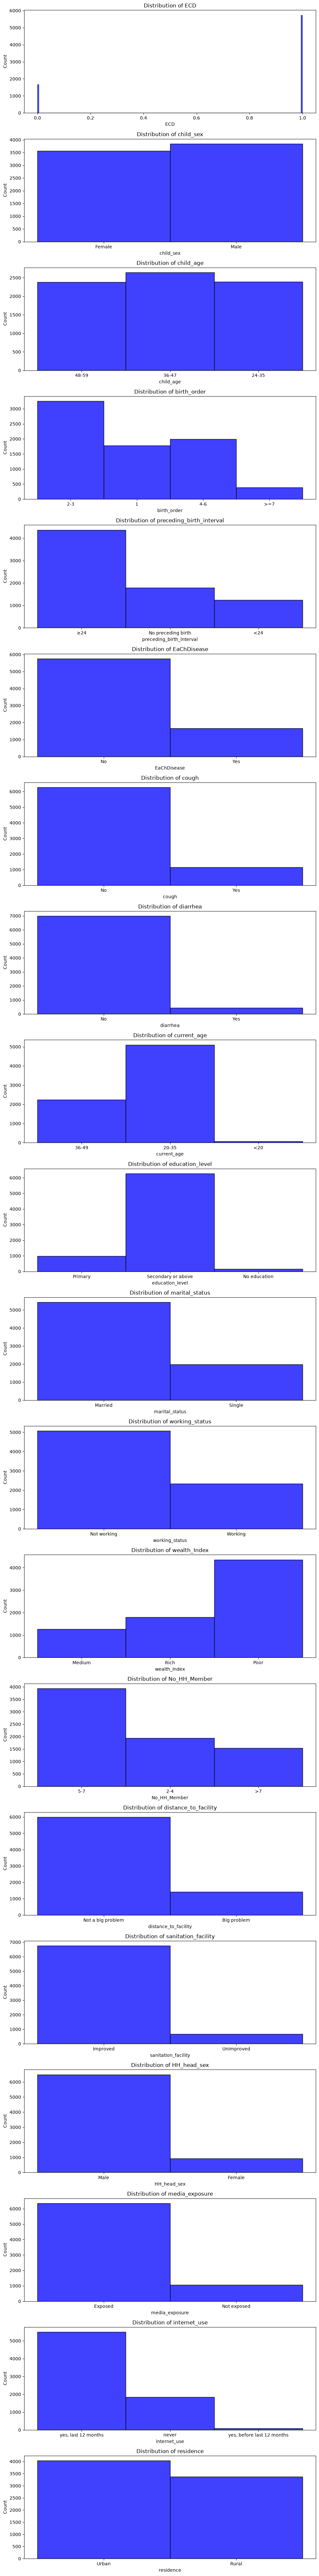

In [9]:
# Plot all the variables using histogram subplots
fig, axes = plt.subplots(nrows=len(data.columns), ncols=1, figsize=(10,len(data.columns)*4))
for i, col in enumerate(data.columns):
    sns.histplot(data[col], ax=axes[i], kde=False, color='b')
    axes[i].set_title(f"Distribution of {col}")
# Show the plot
plt.tight_layout()
plt.show()

In [10]:
from sklearn.preprocessing import LabelEncoder 

In [11]:
# Convert categorical data to numerical data using LabelEncoder 
le = LabelEncoder()
data['child_sex'] = le.fit_transform(data['child_sex'])
data['child_age'] = le.fit_transform(data['child_age'])
data['residence'] = le.fit_transform(data['residence'])
# data['supplemented_VitA'] = le.fit_transform(data['supplemented_VitA'])
# data['drug_intestinal_parasite'] = le.fit_transform(data['drug_intestinal_parasite'])
data['HH_head_sex'] = le.fit_transform(data['HH_head_sex'])
data['birth_order'] = le.fit_transform(data['birth_order'])
data['preceding_birth_interval'] = le.fit_transform(data['preceding_birth_interval'])
data['EaChDisease'] = le.fit_transform(data['EaChDisease'])
data['current_age'] = le.fit_transform(data['current_age'])
data['education_level'] = le.fit_transform(data['education_level'])
data['marital_status'] = le.fit_transform(data['marital_status'])
data['working_status'] = le.fit_transform(data['working_status'])
data['wealth_Index'] = le.fit_transform(data['wealth_Index'])
data['distance_to_facility'] = le.fit_transform(data['distance_to_facility'])
data['media_exposure'] = le.fit_transform(data['media_exposure'])
data['No_HH_Member'] = le.fit_transform(data['No_HH_Member'])
data['diarrhea'] = le.fit_transform(data['diarrhea'])
data['cough'] = le.fit_transform(data['cough'])
data['internet_use'] = le.fit_transform(data['internet_use'])
data['sanitation_facility'] = le.fit_transform(data['sanitation_facility'])

In [12]:
# Now lets see the correlation with in the variables in the dataset
data.corr() #This function is the default pearson correlation function.

,ECD,child_sex,child_age,birth_order,preceding_birth_interval,EaChDisease,cough,diarrhea,current_age,education_level,marital_status,working_status,wealth_Index,No_HH_Member,distance_to_facility,sanitation_facility,HH_head_sex,media_exposure,internet_use,residence
ECD,1.000000,-0.064008,-0.083956,-0.046445,0.008847,0.049417,0.039792,0.029765,-0.007687,0.133750,0.013053,0.056300,0.022366,-0.004044,0.078208,-0.078123,0.017656,-0.089995,0.132479,0.028100
child_sex,-0.064008,1.000000,0.013679,-0.004197,-0.013249,0.004142,0.001873,-0.000065,-0.006256,-0.010665,0.012625,0.013892,0.000198,0.001442,-0.000898,0.005740,-0.009608,0.010175,-0.007474,0.004655
child_age,-0.083956,0.013679,1.000000,0.026321,-0.011220,-0.040988,-0.021861,-0.058837,0.045682,-0.021741,-0.019810,0.058327,0.009363,-0.020317,-0.007415,-0.002582,-0.008102,0.003851,-0.011795,-0.017965
birth_order,-0.046445,-0.004197,0.026321,1.000000,0.257790,-0.002423,0.002914,-0.006063,0.390927,-0.216306,-0.241880,-0.019995,-0.063893,0.399771,-0.100408,-0.010567,0.103173,0.045800,-0.218058,0.008114
preceding_birth_interval,0.008847,-0.013249,-0.011220,0.257790,1.000000,-0.005202,-0.005986,-0.015589,0.178247,-0.004964,-0.035733,0.078840,0.010675,0.053603,0.003592,-0.021061,0.012680,0.013789,-0.053863,-0.063669
EaChDisease,0.049417,0.004142,-0.040988,-0.002423,-0.005202,1.000000,0.796587,0.462062,-0.007740,0.025000,0.039487,0.035992,-0.014679,-0.001161,-0.025314,-0.033473,-0.001223,-0.042774,0.043417,-0.019881
cough,0.039792,0.001873,-0.021861,0.002914,-0.005986,0.796587,1.000000,0.144269,-0.020410,0.018855,0.031734,0.020988,-0.008282,0.010719,-0.020421,-0.023415,-0.002882,-0.035757,0.051084,-0.002601
diarrhea,0.029765,-0.000065,-0.058837,-0.006063,-0.015589,0.462062,0.144269,1.000000,-0.000466,0.016301,0.000700,-0.006538,-0.008871,-0.018278,0.005724,-0.036884,0.019343,-0.008066,0.027889,0.016360
current_age,-0.007687,-0.006256,0.045682,0.390927,0.178247,-0.007740,-0.020410,-0.000466,1.000000,-0.084634,-0.089674,0.100248,0.061652,0.171170,-0.023112,-0.033237,-0.001946,0.001314,-0.127060,-0.023719
education_level,0.133750,-0.010665,-0.021741,-0.216306,-0.004964,0.025000,0.018855,0.016301,-0.084634,1.000000,0.021309,0.059882,0.055076,-0.100144,0.152347,-0.164757,-0.043918,-0.177873,0.316892,0.073989


<Axes: >

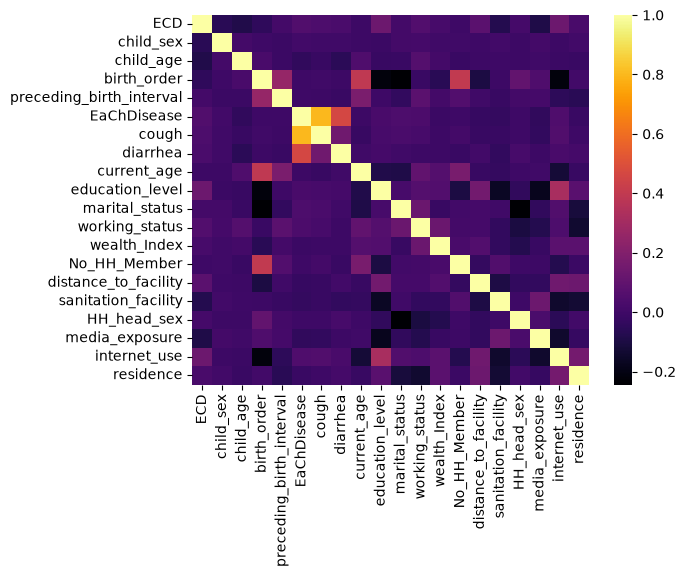

In [13]:
#see the correlation heatmap
sns.heatmap(data.corr(), cmap='inferno') #Very good correlation 

In [14]:
#Building prediction model#

In [15]:
#Before we start training and testing, we need to split our dataset for training and testing
#define the independent and dependent variable
X= data.drop(["ECD"], axis = 1)
Y= data["ECD"]

# Train/Test split
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size = 0.2, random_state = 42)

In [16]:
# Model training
from sklearn.ensemble import RandomForestClassifier
clf = RandomForestClassifier(n_estimators = 500, max_depth = 4, max_features = 3, bootstrap = True, random_state = 18).fit(x_train, y_train)

In [17]:
from sklearn.metrics import classification_report, balanced_accuracy_score
baseline_prediction = clf.predict(x_test)

In [18]:
# Check the model performance
print(classification_report(y_test, baseline_prediction))
print(balanced_accuracy_score(y_test, baseline_prediction))

              precision    recall  f1-score   support

           0       0.00      0.00      0.00       336
           1       0.77      1.00      0.87      1147

    accuracy                           0.77      1483
   macro avg       0.39      0.50      0.44      1483
weighted avg       0.60      0.77      0.67      1483

0.5


/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape

In [19]:
#Baseline Model hyperparameter tuning was done but no significant difference observed.
# Define the Random Forest Regressor
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier()

In [20]:
# Define the parameter grid for Grid Search
param_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [4,6,8, 10],
    'min_samples_leaf': [1, 2, 4],
    'min_samples_split': [2, 5, 10],
    'max_features': ['sqrt', 'log2'],
    'criterion' :['gini', 'entropy'],
    'random_state' : [42]
}

In [21]:
# Define the K-Fold cross-validation
from sklearn.model_selection import KFold
kf = KFold(n_splits=5, shuffle=True, random_state=42)

In [22]:
# Define the Grid Search with K-Fold cross-validation
from sklearn.model_selection import GridSearchCV
grid_search = GridSearchCV(rf, param_grid=param_grid, cv=kf)

In [23]:
# Fit the Grid Search to the ECD dataset
grid_search.fit(X, Y)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestClassifier()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'criterion': ['gini', 'entropy'], 'max_depth': [4, 6, ...], 'max_features': ['sqrt', 'log2'], 'min_samples_leaf': [1, 2, ...], ...}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support 

In [24]:
# Print the best parameters and the best score
print("Best parameters: ", grid_search.best_params_)
print("Best score: ", grid_search.best_score_)

Best parameters:  {'criterion': 'entropy', 'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 150, 'random_state': 42}
Best score:  0.7777630054700005


In [25]:
rf_tuned = RandomForestClassifier(criterion = 'gini', max_depth = 4, max_features= 'sqrt', min_samples_leaf= 1, min_samples_split= 10, n_estimators = 50, random_state = 42).fit(x_train, y_train)
tuned_baseline_prediction = rf_tuned.predict(x_test)

In [26]:
# Check the model performance
print(classification_report(y_test, tuned_baseline_prediction))


              precision    recall  f1-score   support

           0       1.00      0.01      0.01       336
           1       0.77      1.00      0.87      1147

    accuracy                           0.77      1483
   macro avg       0.89      0.50      0.44      1483
weighted avg       0.83      0.77      0.68      1483



In [27]:
# The baseline model was better than the resampled. Therefore we will proceed with the baseline model withone resampling ones.
#please refer to the resampling comparison file. 

In [28]:
# Model 1: RF (Random Forest)

In [29]:
#Grid search (done already) and Train RF
from sklearn.ensemble import RandomForestClassifier 
rfc_tuned = RandomForestClassifier(criterion = 'gini', max_depth = 4, max_features= 'sqrt', min_samples_leaf= 1, min_samples_split= 10, n_estimators = 50, random_state = 42)
rfc_tuned.fit(x_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",50
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",4
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap:

In [30]:
rfc_pred= rfc_tuned.predict(x_test)
print(classification_report(y_test, rfc_pred))
print(f'balanced accuracy:', balanced_accuracy_score(y_test, rfc_pred))

              precision    recall  f1-score   support

           0       1.00      0.01      0.01       336
           1       0.77      1.00      0.87      1147

    accuracy                           0.77      1483
   macro avg       0.89      0.50      0.44      1483
weighted avg       0.83      0.77      0.68      1483

balanced accuracy: 0.5029761904761905


In [31]:
#see the metrics
from sklearn.metrics import confusion_matrix
from sklearn.metrics import recall_score
cm = confusion_matrix(y_test, rfc_pred)

In [32]:
# calculate sensitivity/recall
sensitivity = recall_score(y_test, rfc_pred)
# calculate specificity
specificity = cm[0,0] / (cm[0,0] + cm[0,1])
# print the results
print("Sensitivity:", sensitivity)
print("Specificity:", specificity)

Sensitivity: 1.0
Specificity: 0.005952380952380952


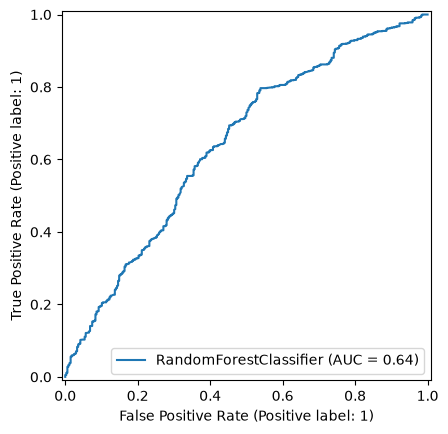

In [33]:
from sklearn.metrics import RocCurveDisplay
rfc_disp = RocCurveDisplay.from_estimator(rfc_tuned, x_test, y_test)
plt.show()

In [34]:
# Model 3: KNN (K nearest Neighbors)

In [35]:
# hyperparameter tuning for KNN
from sklearn.neighbors import KNeighborsClassifier


In [36]:
#KNN Model grid search (done) and training
# Create a K-Nearest Neighbors model
from sklearn.neighbors import KNeighborsClassifier
KNN_tuned = KNeighborsClassifier(n_neighbors=3)

In [37]:
# Train the model using the training sets
KNN_tuned.fit(x_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",3
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [38]:
# Predict the output for the test data
KNNpred = KNN_tuned.predict(x_test)

In [39]:
print(classification_report(y_test, KNNpred))
print(f'balanced accuracy:', balanced_accuracy_score(y_test, KNNpred))

              precision    recall  f1-score   support

           0       0.28      0.15      0.19       336
           1       0.78      0.89      0.83      1147

    accuracy                           0.72      1483
   macro avg       0.53      0.52      0.51      1483
weighted avg       0.67      0.72      0.69      1483

balanced accuracy: 0.5181711088969153


In [40]:
cm = confusion_matrix(y_test, KNNpred)
# calculate sensitivity/recall
sensitivity = recall_score(y_test, KNNpred)
# calculate specificity
specificity = cm[0,0] / (cm[0,0] + cm[0,1])
# print the results
print("Sensitivity:", sensitivity)
print("Specificity:", specificity)

Sensitivity: 0.8875326939843069
Specificity: 0.1488095238095238


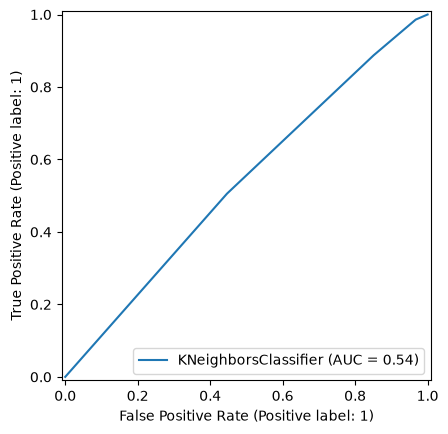

In [41]:
from sklearn.metrics import RocCurveDisplay
rfc_disp = RocCurveDisplay.from_estimator(KNN_tuned, x_test, y_test)
plt.show()

In [42]:
# Model 4: SVM (Support vector machine)

In [43]:
#SVM gride search (done) and model training
from sklearn.svm import SVC
svc_tuned = SVC(probability=True, C= 1, gamma= 1, kernel= 'rbf')
svc_tuned.fit(x_train, y_train)

/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",1
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",True
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [44]:
svc_pred= svc_tuned.predict(x_test)
print(classification_report(y_test, svc_pred))
print(f'balanced accuracy:', balanced_accuracy_score(y_test, svc_pred))

              precision    recall  f1-score   support

           0       0.34      0.04      0.06       336
           1       0.78      0.98      0.87      1147

    accuracy                           0.77      1483
   macro avg       0.56      0.51      0.47      1483
weighted avg       0.68      0.77      0.68      1483

balanced accuracy: 0.5078309876696974


In [45]:
cm = confusion_matrix(y_test, svc_pred)
# calculate sensitivity/recall
sensitivity = recall_score(y_test, svc_pred)
# calculate specificity
specificity = cm[0,0] / (cm[0,0] + cm[0,1])
# print the results
print("Sensitivity:", sensitivity)
print("Specificity:", specificity)

Sensitivity: 0.979947689625109
Specificity: 0.03571428571428571


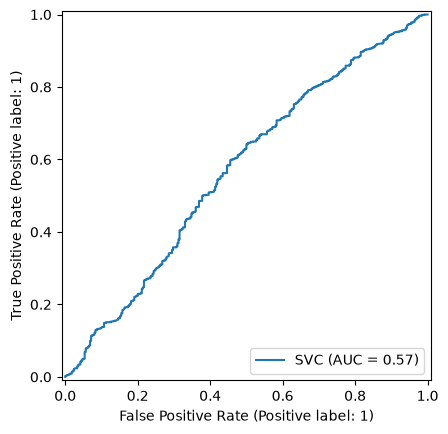

In [46]:
from sklearn.metrics import RocCurveDisplay
rfc_disp = RocCurveDisplay.from_estimator(svc_tuned, x_test, y_test)
plt.show()

In [47]:
# Model 5: NB (Nieve bays)

In [48]:
#NB grid search (done) and model training
from sklearn.naive_bayes import GaussianNB
nb_tuned = GaussianNB(var_smoothing= 0.008111308307896872)
nb_tuned.fit(x_train, y_train)

,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",0.008111308307896872
,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[1335.,4593.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.23,0.77]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](2,)","[0,1]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,0.006039
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](19,)","['child_sex','child_age','birth_order',...,'media_exposure','internet_use', 'residence']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,19
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 19)","[[0.58,1.14,1.21,...,0.2 ,1.29,0.52], [0.51,0.97,1.11,...,0.13,1.56,0.55]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 19)","[[0.25,0.66,0.74,...,0.17,0.91,0.26], [0.26,0.64,0.69,...,0.12,0.69,0.25]]"


In [49]:
Nbpred = nb_tuned.predict(x_test)

In [50]:
print(classification_report(y_test, Nbpred))
print(f'balanced accuracy:', balanced_accuracy_score(y_test, Nbpred))

              precision    recall  f1-score   support

           0       0.42      0.32      0.36       336
           1       0.81      0.87      0.84      1147

    accuracy                           0.75      1483
   macro avg       0.62      0.60      0.60      1483
weighted avg       0.72      0.75      0.73      1483

balanced accuracy: 0.5951459812346909


In [51]:
cm = confusion_matrix(y_test, Nbpred)
# calculate sensitivity/recall
sensitivity = recall_score(y_test, Nbpred)
# calculate specificity
specificity = cm[0,0] / (cm[0,0] + cm[0,1])
# print the results
print("Sensitivity:", sensitivity)
print("Specificity:", specificity)

Sensitivity: 0.8718395815170009
Specificity: 0.31845238095238093


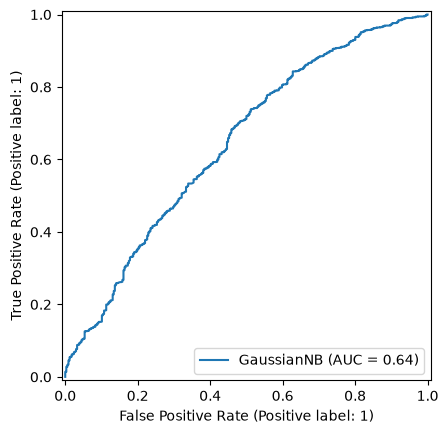

In [52]:
from sklearn.metrics import RocCurveDisplay
rfc_disp = RocCurveDisplay.from_estimator(nb_tuned, x_test, y_test)
plt.show()

In [53]:
# Model 6: LR (Logistic regression)

In [54]:
#LR grid search (done) and model training
from sklearn.linear_model import LogisticRegression
lr_tuned = LogisticRegression(C=10, penalty = 'l2')
lr_tuned.fit(x_train, y_train)

/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'l2'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",10
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:

In [55]:
# Predict the output for the test data
LRpred = lr_tuned.predict(x_test)
print(classification_report(y_test, LRpred))
print(f'balanced accuracy:', balanced_accuracy_score(y_test, LRpred))

              precision    recall  f1-score   support

           0       0.50      0.03      0.06       336
           1       0.78      0.99      0.87      1147

    accuracy                           0.77      1483
   macro avg       0.64      0.51      0.47      1483
weighted avg       0.71      0.77      0.69      1483

balanced accuracy: 0.5115739299207042


In [56]:
cm = confusion_matrix(y_test, LRpred)
# calculate sensitivity/recall
sensitivity = recall_score(y_test, LRpred)
# calculate specificity
specificity = cm[0,0] / (cm[0,0] + cm[0,1])
# print the results
print("Sensitivity:", sensitivity)
print("Specificity:", specificity)

Sensitivity: 0.990409764603313
Specificity: 0.03273809523809524


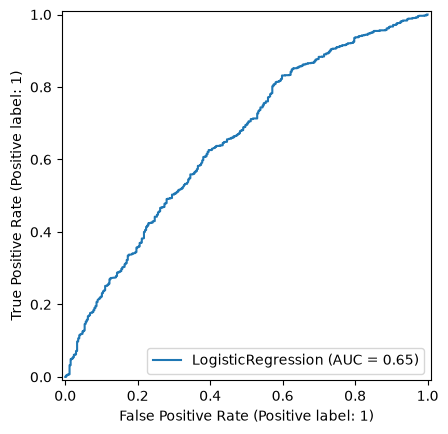

In [57]:
from sklearn.metrics import RocCurveDisplay
rfc_disp = RocCurveDisplay.from_estimator(lr_tuned, x_test, y_test)
plt.show()

In [58]:
# Model 7: GB (Gradiant boosting)

In [59]:
#GB grid search (done) and model training
from sklearn.ensemble import GradientBoostingClassifier
gb_tuned = GradientBoostingClassifier(learning_rate=0.1, n_estimators=200, max_depth=5)
gb_tuned.fit(x_train, y_train)

,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",200
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",5
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"init init: estimator or 'zero', default=NoneAn estimator object that is used to co

In [60]:
# Make predictions on the test set
GBpred = gb_tuned.predict(x_test)

In [61]:
# Print the classification report
print(classification_report(y_test, GBpred))
print(f'balanced accuracy:', balanced_accuracy_score(y_test, GBpred))

              precision    recall  f1-score   support

           0       0.47      0.13      0.21       336
           1       0.79      0.96      0.87      1147

    accuracy                           0.77      1483
   macro avg       0.63      0.55      0.54      1483
weighted avg       0.72      0.77      0.72      1483

balanced accuracy: 0.5451682961763608


In [62]:
cm = confusion_matrix(y_test, GBpred)
# calculate sensitivity/recall
sensitivity = recall_score(y_test, GBpred)
# calculate specificity
specificity = cm[0,0] / (cm[0,0] + cm[0,1])
# print the results
print("Sensitivity:", sensitivity)
print("Specificity:", specificity)

Sensitivity: 0.95640802092415
Specificity: 0.13392857142857142


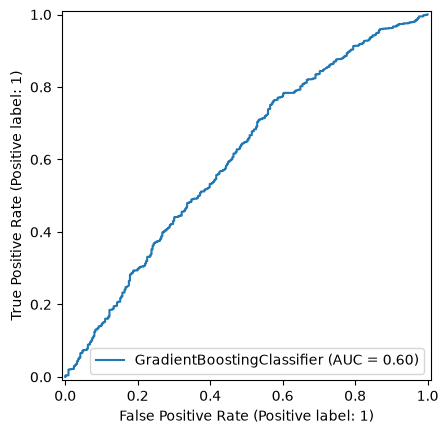

In [63]:
from sklearn.metrics import RocCurveDisplay
rfc_disp = RocCurveDisplay.from_estimator(gb_tuned, x_test, y_test)
plt.show()

In [64]:
# Model 8: XGB (eXtreme gradiant boosting)

In [65]:
#XGB grid search(done) and model training
get_ipython().system('pip install xgboost')
from xgboost import XGBClassifier
xgb_tuned=XGBClassifier(learning_rate= 0.01, max_depth= 3, n_estimators= 200)
xgb_tuned.fit(x_train, y_train)


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python3 -m pip install --upgrade pip


,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [66]:
XGBpred= xgb_tuned.predict(x_test)
print(classification_report(y_test, XGBpred))
print(f'balanced accuracy:', balanced_accuracy_score(y_test, XGBpred))

              precision    recall  f1-score   support

           0       0.50      0.01      0.01       336
           1       0.77      1.00      0.87      1147

    accuracy                           0.77      1483
   macro avg       0.64      0.50      0.44      1483
weighted avg       0.71      0.77      0.68      1483

balanced accuracy: 0.5021043508946735


In [67]:
cm = confusion_matrix(y_test, XGBpred)
# calculate sensitivity/recall
sensitivity = recall_score(y_test, XGBpred)
# calculate specificity
specificity = cm[0,0] / (cm[0,0] + cm[0,1])
# print the results
print("Sensitivity:", sensitivity)
print("Specificity:", specificity)

Sensitivity: 0.998256320836966
Specificity: 0.005952380952380952


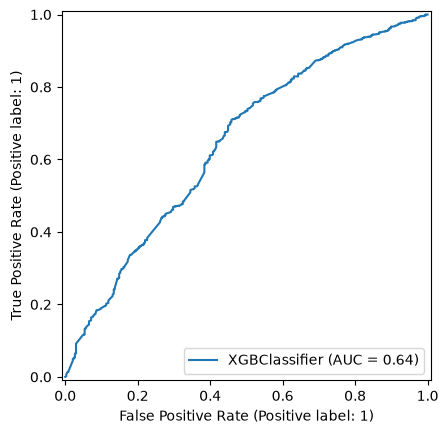

In [68]:
from sklearn.metrics import RocCurveDisplay
rfc_disp = RocCurveDisplay.from_estimator(xgb_tuned, x_test, y_test)
plt.show()

In [69]:
# Model 8: Ensemble Learning 

In [70]:
# Import required libraries
from sklearn.ensemble import VotingClassifier

In [71]:
# Create an ensemble model using VotingClassifier
ensemble_model = VotingClassifier(estimators=[('rf',rfc_tuned), ('xgb', xgb_tuned)], voting='soft')

In [72]:
# Fit the ensemble model to the data
ensemble_model.fit(x_train, y_train)

,"estimators estimators: list of (str, estimator) tuplesInvoking the ``fit`` method on the ``VotingClassifier`` will fit clonesof those original estimators that will be stored in the class attribute``self.estimators_``. An estimator can be set to ``'drop'`` using:meth:`set_params`... versionchanged:: 0.21 ``'drop'`` is accepted. Using None was deprecated in 0.22 and support was removed in 0.24.","[('rf', ...), ('xgb', ...)]"
,"voting voting: {'hard', 'soft'}, default='hard'If 'hard', uses predicted class labels for majority rule voting.Else if 'soft', predicts the class label based on the argmax ofthe sums of the predicted probabilities, which is recommended foran ensemble of well-calibrated classifiers.",'soft'
,"weights weights: array-like of shape (n_classifiers,), default=NoneSequence of weights (`float` or `int`) to weight the occurrences ofpredicted class labels (`hard` voting) or class probabilitiesbefore averaging (`soft` voting). Uses uniform weights if `None`.",None
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for ``fit``.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionadded:: 0.18",None
,"flatten_transform flatten_transform: bool, default=TrueAffects shape of transform output only when voting='soft'If voting='soft' and flatten_transform=True, transform method returnsmatrix with shape (n_samples, n_classifiers * n_classes). Ifflatten_transform=False, it returns(n_classifiers, n_samples, n_classes).",True
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting will be printed as itis completed... versionadded:: 0.23",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[int64](2,)","[0,1]"
"estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators as defined in ``estimators``that are not 'drop'. Note that sub-estimators are always fitted oninteger-encoded labels (see ``le_`` attribute). When ``y`` containsnon-integer class labels (e.g. strings), use ``le_.inverse_transform``to map predictions back to the original label space.",list,"[RandomForestC...ndom_state=42), XGBClassifier...ree=None, ...)]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimators expose such an attribute when fit... versionadded:: 1.0","ndarray[<U24](19,)","['child_sex','child_age','birth_order',...,'media_exposure','internet_use', 'residence']"
le_ le_: :class:`~sklearn.preprocessing.LabelEncoder`Transformer used to encode the labels during fit and decode duringprediction. Sub-estimators in ``estimators_`` are fitted on theinteger-encoded labels produced by this encoder.,LabelEncoder,LabelEncoder()


In [73]:
# Predict the target variable
y_pred_ensemble = ensemble_model.predict(x_train)

In [74]:
print(classification_report(y_train, y_pred_ensemble))
print(f'balanced accuracy:', balanced_accuracy_score(y_train, y_pred_ensemble))

              precision    recall  f1-score   support

           0       0.87      0.01      0.02      1335
           1       0.78      1.00      0.87      4593

    accuracy                           0.78      5928
   macro avg       0.82      0.50      0.45      5928
weighted avg       0.80      0.78      0.68      5928

balanced accuracy: 0.5046511912362975


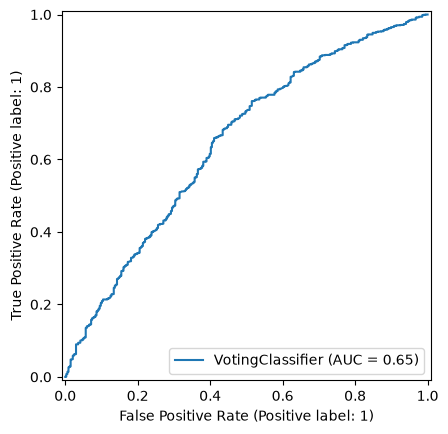

In [75]:
from sklearn.metrics import RocCurveDisplay
rfc_disp = RocCurveDisplay.from_estimator(ensemble_model, x_test, y_test)
plt.show()

In [76]:
# Ensure the predictions have the same number of samples
min_samples = min(len(rfc_pred), len(XGBpred))
rfc_predictions = rfc_pred[:min_samples]
xgb_predictions = XGBpred[:min_samples]
y_test = y_test[:min_samples]

In [77]:
ensemble_predictions = []
for i in range(len(y_test)):
    # Majority voting
    votes = rfc_pred[i] + XGBpred[i]
    ensemble_predictions.append(1 if votes >= 2 else 0)

In [78]:
cm = confusion_matrix(y_test, ensemble_predictions)
# calculate sensitivity/recall
sensitivity = recall_score(y_test, ensemble_predictions)
# calculate specificity
specificity = cm[0,0] / (cm[0,0] + cm[0,1])
# print the results
print("Sensitivity:", sensitivity)
print("Specificity:", specificity)

Sensitivity: 0.998256320836966
Specificity: 0.005952380952380952


In [79]:
#So, the ensemble prediction provided the best model.
#plot all the roc curves in one plot
# Compute the ROC curve and AUC for each model
rf_probablities = rfc_tuned.predict_proba(x_test)[:, 1]
knn_probablities = KNN_tuned.predict_proba(x_test)[:, 1]
nb_probablities = nb_tuned.predict_proba(x_test)[:, 1]
lr_probablities = lr_tuned.predict_proba(x_test)[:, 1]
svm_probabilities = svc_tuned.predict_proba(x_test)[:, 1]
xg_probabilities = gb_tuned.predict_proba(x_test)[:, 1]
xgb_probabilities = xgb_tuned.predict_proba(x_test)[:, 1]
ensemble_probablities = ensemble_model.predict_proba(x_test)[:, 1]

In [80]:
# Compute the ROC curve and AUC for each model
from sklearn.metrics import roc_curve
from sklearn.metrics import auc

svm_fpr, svm_tpr, _ = roc_curve(y_test, svm_probabilities)
svm_auc = auc(svm_fpr, svm_tpr)

rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_probablities)
rf_auc = auc(rf_fpr, rf_tpr)

knn_fpr, knn_tpr, _ = roc_curve(y_test, knn_probablities)
knn_auc = auc(knn_fpr, knn_tpr)

nb_fpr, nb_tpr, _ = roc_curve(y_test, nb_probablities)
nb_auc = auc(nb_fpr, nb_tpr)

lr_fpr, lr_tpr, _ = roc_curve(y_test, lr_probablities)
lr_auc = auc(lr_fpr, lr_tpr)

xg_fpr, xg_tpr, _ = roc_curve(y_test, xg_probabilities)
xg_auc = auc(xg_fpr, xg_tpr)

xgb_fpr, xgb_tpr, _ = roc_curve(y_test, xgb_probabilities)
xgb_auc = auc(xgb_fpr, xgb_tpr)

ensemble_fpr, ensemble_tpr, _ = roc_curve(y_test, ensemble_probablities)
ensemble_auc = auc(ensemble_fpr, ensemble_tpr)

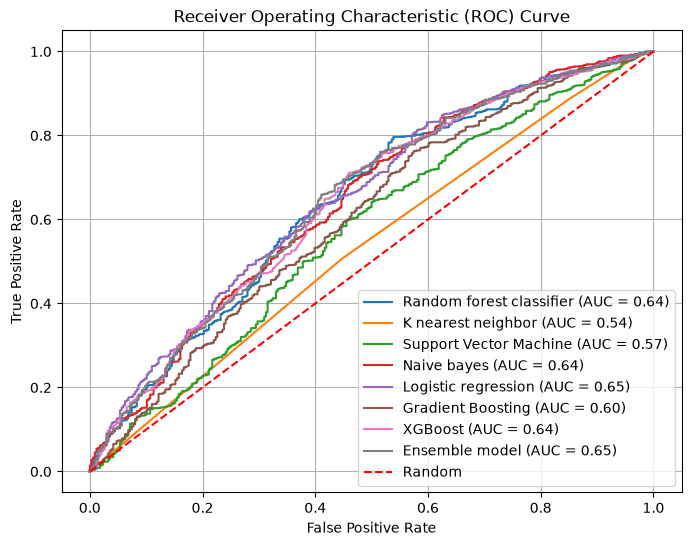

In [81]:
# Plot the ROC curves
plt.figure(figsize=(8, 6))
plt.plot(rf_fpr, rf_tpr, label='Random forest classifier (AUC = {:.2f})'.format(rf_auc))
plt.plot(knn_fpr, knn_tpr, label='K nearest neighbor (AUC = {:.2f})'.format(knn_auc))
plt.plot(svm_fpr, svm_tpr, label='Support Vector Machine (AUC = {:.2f})'.format(svm_auc))
plt.plot(nb_fpr, nb_tpr, label='Naive bayes (AUC = {:.2f})'.format(nb_auc))
plt.plot(lr_fpr, lr_tpr, label='Logistic regression (AUC = {:.2f})'.format(lr_auc))
plt.plot(xg_fpr, xg_tpr, label='Gradient Boosting (AUC = {:.2f})'.format(xg_auc))
plt.plot(xgb_fpr, xgb_tpr, label='XGBoost (AUC = {:.2f})'.format(xgb_auc))
plt.plot(ensemble_fpr, ensemble_tpr, label='Ensemble model (AUC = {:.2f})'.format(ensemble_auc))
plt.plot([0, 1], [0, 1], linestyle='--', color='r', label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend()
plt.grid(True)
plt.savefig('ROC.tiff', bbox_inches="tight",dpi = 700)

In [82]:
# Model 9: Ensemble Learning (NB and LR)

In [83]:
# Import required libraries
from sklearn.ensemble import VotingClassifier
# Create an ensemble model using VotingClassifier
ensemble_model1 = VotingClassifier(estimators=[('nb',nb_tuned), ('lr', lr_tuned)], voting='soft')

In [84]:
# Fit the ensemble model to the data
ensemble_model1.fit(x_train, y_train)

/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


,"estimators estimators: list of (str, estimator) tuplesInvoking the ``fit`` method on the ``VotingClassifier`` will fit clonesof those original estimators that will be stored in the class attribute``self.estimators_``. An estimator can be set to ``'drop'`` using:meth:`set_params`... versionchanged:: 0.21 ``'drop'`` is accepted. Using None was deprecated in 0.22 and support was removed in 0.24.","[('nb', ...), ('lr', ...)]"
,"voting voting: {'hard', 'soft'}, default='hard'If 'hard', uses predicted class labels for majority rule voting.Else if 'soft', predicts the class label based on the argmax ofthe sums of the predicted probabilities, which is recommended foran ensemble of well-calibrated classifiers.",'soft'
,"weights weights: array-like of shape (n_classifiers,), default=NoneSequence of weights (`float` or `int`) to weight the occurrences ofpredicted class labels (`hard` voting) or class probabilitiesbefore averaging (`soft` voting). Uses uniform weights if `None`.",None
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for ``fit``.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionadded:: 0.18",None
,"flatten_transform flatten_transform: bool, default=TrueAffects shape of transform output only when voting='soft'If voting='soft' and flatten_transform=True, transform method returnsmatrix with shape (n_samples, n_classifiers * n_classes). Ifflatten_transform=False, it returns(n_classifiers, n_samples, n_classes).",True
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting will be printed as itis completed... versionadded:: 0.23",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[int64](2,)","[0,1]"
"estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators as defined in ``estimators``that are not 'drop'. Note that sub-estimators are always fitted oninteger-encoded labels (see ``le_`` attribute). When ``y`` containsnon-integer class labels (e.g. strings), use ``le_.inverse_transform``to map predictions back to the original label space.",list,"[GaussianNB(va...1308307896872), LogisticRegre... penalty='l2')]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimators expose such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['child_sex','child_age','birth_order',...,'media_exposure','internet_use', 'residence']"
le_ le_: :class:`~sklearn.preprocessing.LabelEncoder`Transformer used to encode the labels during fit and decode duringprediction. Sub-estimators in ``estimators_`` are fitted on theinteger-encoded labels produced by this encoder.,LabelEncoder,LabelEncoder()


In [85]:
# Predict the target variable
y_pred_ensemble1 = ensemble_model1.predict(x_train)
print(classification_report(y_train, y_pred_ensemble1))
print(f'balanced accuracy:', balanced_accuracy_score(y_train, y_pred_ensemble1))

              precision    recall  f1-score   support

           0       0.41      0.20      0.27      1335
           1       0.80      0.92      0.85      4593

    accuracy                           0.76      5928
   macro avg       0.61      0.56      0.56      5928
weighted avg       0.71      0.76      0.72      5928

balanced accuracy: 0.5597912798420654


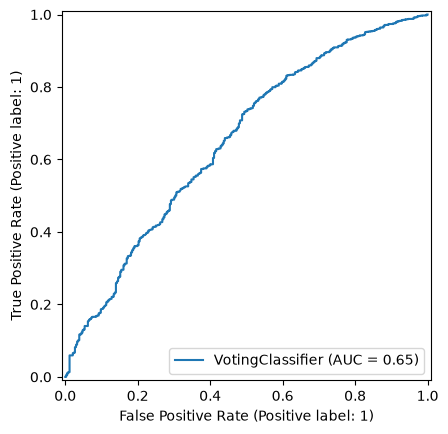

In [86]:
from sklearn.metrics import RocCurveDisplay
rfc_disp1 = RocCurveDisplay.from_estimator(ensemble_model1, x_test, y_test)
plt.show()

In [87]:
# Ensure the predictions have the same number of samples
min_samples1 = min(len(Nbpred), len(LRpred))
nb_predictions1 = Nbpred[:min_samples1]
lr_predictions1 = LRpred[:min_samples1]
y_test1 = y_test[:min_samples1]

In [88]:
ensemble_predictions1 = []
for i in range(len(y_test1)):
    # Majority voting
    votes = Nbpred[i] + LRpred[i]
    ensemble_predictions1.append(1 if votes >= 2 else 0)

In [89]:
cm1 = confusion_matrix(y_test1, ensemble_predictions1)
# calculate sensitivity/recall
sensitivity1 = recall_score(y_test1, ensemble_predictions1)
# calculate specificity
specificity1 = cm1[0,0] / (cm1[0,0] + cm1[0,1])
# print the results
print("Sensitivity:", sensitivity1)
print("Specificity:", specificity1)

Sensitivity: 0.8718395815170009
Specificity: 0.31845238095238093


In [90]:
# Model 10: Ensemble Learning (NB and GB)

In [91]:
# Import required libraries
from sklearn.ensemble import VotingClassifier
# Create an ensemble model using VotingClassifier
ensemble_model2 = VotingClassifier(estimators=[('nb',nb_tuned), ('gb', gb_tuned)], voting='soft')

In [92]:
# Fit the ensemble model to the data
ensemble_model2.fit(x_train, y_train)

,"estimators estimators: list of (str, estimator) tuplesInvoking the ``fit`` method on the ``VotingClassifier`` will fit clonesof those original estimators that will be stored in the class attribute``self.estimators_``. An estimator can be set to ``'drop'`` using:meth:`set_params`... versionchanged:: 0.21 ``'drop'`` is accepted. Using None was deprecated in 0.22 and support was removed in 0.24.","[('nb', ...), ('gb', ...)]"
,"voting voting: {'hard', 'soft'}, default='hard'If 'hard', uses predicted class labels for majority rule voting.Else if 'soft', predicts the class label based on the argmax ofthe sums of the predicted probabilities, which is recommended foran ensemble of well-calibrated classifiers.",'soft'
,"weights weights: array-like of shape (n_classifiers,), default=NoneSequence of weights (`float` or `int`) to weight the occurrences ofpredicted class labels (`hard` voting) or class probabilitiesbefore averaging (`soft` voting). Uses uniform weights if `None`.",None
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for ``fit``.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionadded:: 0.18",None
,"flatten_transform flatten_transform: bool, default=TrueAffects shape of transform output only when voting='soft'If voting='soft' and flatten_transform=True, transform method returnsmatrix with shape (n_samples, n_classifiers * n_classes). Ifflatten_transform=False, it returns(n_classifiers, n_samples, n_classes).",True
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting will be printed as itis completed... versionadded:: 0.23",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[int64](2,)","[0,1]"
"estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators as defined in ``estimators``that are not 'drop'. Note that sub-estimators are always fitted oninteger-encoded labels (see ``le_`` attribute). When ``y`` containsnon-integer class labels (e.g. strings), use ``le_.inverse_transform``to map predictions back to the original label space.",list,"[GaussianNB(va...1308307896872), GradientBoost...stimators=200)]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimators expose such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['child_sex','child_age','birth_order',...,'media_exposure','internet_use', 'residence']"
le_ le_: :class:`~sklearn.preprocessing.LabelEncoder`Transformer used to encode the labels during fit and decode duringprediction. Sub-estimators in ``estimators_`` are fitted on theinteger-encoded labels produced by this encoder.,LabelEncoder,LabelEncoder()


In [93]:
# Predict the target variable
y_pred_ensemble2 = ensemble_model2.predict(x_train)
print(classification_report(y_train, y_pred_ensemble2))
print(f'balanced accuracy:', balanced_accuracy_score(y_train, y_pred_ensemble2))

              precision    recall  f1-score   support

           0       0.54      0.28      0.37      1335
           1       0.82      0.93      0.87      4593

    accuracy                           0.78      5928
   macro avg       0.68      0.61      0.62      5928
weighted avg       0.75      0.78      0.76      5928

balanced accuracy: 0.6051783735386287


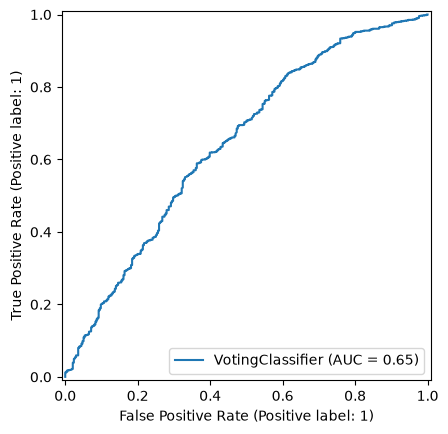

In [94]:
from sklearn.metrics import RocCurveDisplay
rfc_disp2 = RocCurveDisplay.from_estimator(ensemble_model2, x_test, y_test)
plt.show()

In [95]:
# Ensure the predictions have the same number of samples
min_samples2 = min(len(Nbpred), len(GBpred))
nb_predictions2 = Nbpred[:min_samples2]
gb_predictions2 = GBpred[:min_samples2]
y_test2 = y_test[:min_samples2]

In [96]:
ensemble_predictions2 = []
for i in range(len(y_test2)):
    # Majority voting
    votes = Nbpred[i] + GBpred[i]
    ensemble_predictions2.append(1 if votes >= 2 else 0)

In [97]:
cm2 = confusion_matrix(y_test2, ensemble_predictions2)
# calculate sensitivity/recall
sensitivity2 = recall_score(y_test2, ensemble_predictions2)
# calculate specificity
specificity2 = cm2[0,0] / (cm2[0,0] + cm2[0,1])
# print the results
print("Sensitivity:", sensitivity2)
print("Specificity:", specificity2)

Sensitivity: 0.8526591107236269
Specificity: 0.33630952380952384


In [98]:
# Model 11: Ensemble Learning (NB and LR, GB)

In [99]:
# Import required libraries
from sklearn.ensemble import VotingClassifier
# Create an ensemble model using VotingClassifier
ensemble_model3 = VotingClassifier(estimators=[('nb',nb_tuned), ('lr', lr_tuned), ('gb', gb_tuned)], voting='soft')

In [100]:
# Fit the ensemble model to the data
ensemble_model3.fit(x_train, y_train)

/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


,"estimators estimators: list of (str, estimator) tuplesInvoking the ``fit`` method on the ``VotingClassifier`` will fit clonesof those original estimators that will be stored in the class attribute``self.estimators_``. An estimator can be set to ``'drop'`` using:meth:`set_params`... versionchanged:: 0.21 ``'drop'`` is accepted. Using None was deprecated in 0.22 and support was removed in 0.24.","[('nb', ...), ('lr', ...), ...]"
,"voting voting: {'hard', 'soft'}, default='hard'If 'hard', uses predicted class labels for majority rule voting.Else if 'soft', predicts the class label based on the argmax ofthe sums of the predicted probabilities, which is recommended foran ensemble of well-calibrated classifiers.",'soft'
,"weights weights: array-like of shape (n_classifiers,), default=NoneSequence of weights (`float` or `int`) to weight the occurrences ofpredicted class labels (`hard` voting) or class probabilitiesbefore averaging (`soft` voting). Uses uniform weights if `None`.",None
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for ``fit``.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionadded:: 0.18",None
,"flatten_transform flatten_transform: bool, default=TrueAffects shape of transform output only when voting='soft'If voting='soft' and flatten_transform=True, transform method returnsmatrix with shape (n_samples, n_classifiers * n_classes). Ifflatten_transform=False, it returns(n_classifiers, n_samples, n_classes).",True
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting will be printed as itis completed... versionadded:: 0.23",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[int64](2,)","[0,1]"
"estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators as defined in ``estimators``that are not 'drop'. Note that sub-estimators are always fitted oninteger-encoded labels (see ``le_`` attribute). When ``y`` containsnon-integer class labels (e.g. strings), use ``le_.inverse_transform``to map predictions back to the original label space.",list,"[GaussianNB(va...1308307896872), LogisticRegre... penalty='l2'), GradientBoost...stimators=200)]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimators expose such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['child_sex','child_age','birth_order',...,'media_exposure','internet_use', 'residence']"
le_ le_: :class:`~sklearn.preprocessing.LabelEncoder`Transformer used to encode the labels during fit and decode duringprediction. Sub-estimators in ``estimators_`` are fitted on theinteger-encoded labels produced by this encoder.,LabelEncoder,LabelEncoder()


In [101]:
# Predict the target variable
y_pred_ensemble3 = ensemble_model2.predict(x_train)
print(classification_report(y_train, y_pred_ensemble3))
print(f'balanced accuracy:', balanced_accuracy_score(y_train, y_pred_ensemble3))

              precision    recall  f1-score   support

           0       0.54      0.28      0.37      1335
           1       0.82      0.93      0.87      4593

    accuracy                           0.78      5928
   macro avg       0.68      0.61      0.62      5928
weighted avg       0.75      0.78      0.76      5928

balanced accuracy: 0.6051783735386287


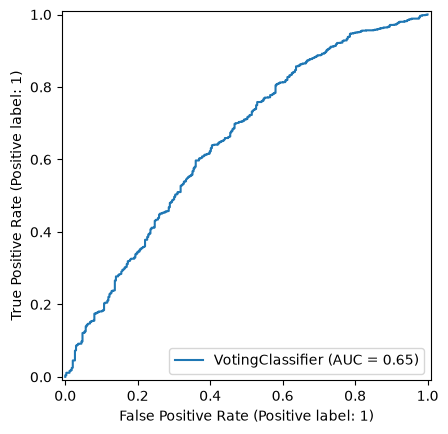

In [102]:
from sklearn.metrics import RocCurveDisplay
rfc_disp3 = RocCurveDisplay.from_estimator(ensemble_model3, x_test, y_test)
plt.show()